# Diabetes Prediction Using Machine Learning



## 1. Import Required Libraries



In [1]:
from pathlib import Path
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

## 2. Define Project Paths


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_RELATIVE_PATH = Path("data") / "processed" / "diabetes_cleaned.csv"
TABLES_RELATIVE_DIR = Path("outputs") / "tables" / "week_09"
FIGURES_RELATIVE_DIR = Path("outputs") / "figures" / "week_09"
REPORTS_RELATIVE_DIR = Path("reports") / "week_09"
MODELS_RELATIVE_DIR = Path("models")

DATASET_PATH = PROJECT_ROOT / DATASET_RELATIVE_PATH
TABLES_DIR = PROJECT_ROOT / TABLES_RELATIVE_DIR
FIGURES_DIR = PROJECT_ROOT / FIGURES_RELATIVE_DIR
REPORTS_DIR = PROJECT_ROOT / REPORTS_RELATIVE_DIR
MODELS_DIR = PROJECT_ROOT / MODELS_RELATIVE_DIR

for directory in [TABLES_DIR, FIGURES_DIR, REPORTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Dataset path: {DATASET_RELATIVE_PATH}")
print(f"Tables directory: {TABLES_RELATIVE_DIR}")
print(f"Figures directory: {FIGURES_RELATIVE_DIR}")
print(f"Reports directory: {REPORTS_RELATIVE_DIR}")

Dataset path: data\processed\diabetes_cleaned.csv
Tables directory: outputs\tables\week_09
Figures directory: outputs\figures\week_09
Reports directory: reports\week_09


## 3. Load and Validate Dataset



In [3]:
EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Required dataset was not found: {DATASET_RELATIVE_PATH}")

df = pd.read_csv(DATASET_PATH)
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(EXPECTED_COLUMNS))

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if extra_columns:
    raise ValueError(f"Unexpected columns found: {extra_columns}")

if df.isna().sum().sum() != 0:
    raise ValueError("The cleaned dataset contains missing values. Week 9 requires a fully cleaned dataset.")

print("Cleaned dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Cleaned dataset loaded successfully.
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 4. Define Feature Sets



In [4]:
TARGET_COLUMN = "Outcome"
ALL_FEATURES = [column for column in EXPECTED_COLUMNS if column != TARGET_COLUMN]
SELECTED_FEATURES = [
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies",
    "DiabetesPedigreeFunction",
]

feature_sets = {
    "Experiment A - All Features": ALL_FEATURES,
    "Experiment B - Selected Features": SELECTED_FEATURES,
}

feature_set_summary = pd.DataFrame([
    {
        "experiment": experiment_name,
        "feature_count": len(features),
        "features": ", ".join(features),
    }
    for experiment_name, features in feature_sets.items()
])

feature_set_summary.to_csv(TABLES_DIR / "feature_set_summary.csv", index=False)
display(feature_set_summary)

,experiment,feature_count,features
0,Experiment A - All Features,8,"Pregnancies, Glucose, BloodPressure, SkinThick..."
1,Experiment B - Selected Features,5,"Glucose, BMI, Age, Pregnancies, DiabetesPedigr..."


## 5. Create Identical Train/Test Split

A single stratified 80/20 split is created using the row index and target variable. The same train and test indices are reused for both experiments to make the comparison fair.

In [13]:
y = df[TARGET_COLUMN]
train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

train_indices = pd.Index(train_indices).sort_values()
test_indices = pd.Index(test_indices).sort_values()

y_train = df.loc[train_indices, TARGET_COLUMN]
y_test = df.loc[test_indices, TARGET_COLUMN]

split_summary = pd.DataFrame([
    {"split": "train", "rows": len(train_indices), "outcome_0": int((y_train == 0).sum()), "outcome_1": int((y_train == 1).sum())},
    {"split": "test", "rows": len(test_indices), "outcome_0": int((y_test == 0).sum()), "outcome_1": int((y_test == 1).sum())},
])

split_indices = pd.DataFrame({
    "row_index": list(train_indices) + list(test_indices),
    "split": ["train"] * len(train_indices) + ["test"] * len(test_indices),
})

split_summary.to_csv(TABLES_DIR / "train_test_split_summary.csv", index=False)
split_indices.to_csv(TABLES_DIR / "train_test_split_indices.csv", index=False)

display(split_summary)

,split,rows,outcome_0,outcome_1
0,train,614,400,214
1,test,154,100,54


## 6. Define Baseline Algorithms



In [6]:
model_definitions = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier()),
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=RANDOM_STATE)),
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("model", GaussianNB()),
    ]),
}

algorithm_summary = pd.DataFrame([
    {
        "algorithm": algorithm_name,
        "pipeline_steps": " -> ".join(pipeline.named_steps.keys()),
        "uses_standard_scaler": "scaler" in pipeline.named_steps,
    }
    for algorithm_name, pipeline in model_definitions.items()
])

algorithm_summary.to_csv(TABLES_DIR / "algorithm_summary.csv", index=False)
display(algorithm_summary)

,algorithm,pipeline_steps,uses_standard_scaler
0,Logistic Regression,scaler -> model,True
1,Decision Tree,model,False
2,Random Forest,model,False
3,K-Nearest Neighbors,scaler -> model,True
4,Support Vector Machine,scaler -> model,True
5,Gaussian Naive Bayes,model,False


## 7. Train and Evaluate Baseline Models

Each algorithm is trained once on all features and once on selected features. Preprocessing is fitted only on the training data because scalers are placed inside sklearn pipelines and `.fit()` is called only on `X_train`.

In [7]:
def get_positive_class_score(fitted_pipeline, X_test_values):
    if hasattr(fitted_pipeline, "predict_proba"):
        return fitted_pipeline.predict_proba(X_test_values)[:, 1]
    if hasattr(fitted_pipeline, "decision_function"):
        return fitted_pipeline.decision_function(X_test_values)
    return None

results = []
confusion_rows = []
model_paths = []

for experiment_name, feature_columns in feature_sets.items():
    X_train = df.loc[train_indices, feature_columns]
    X_test = df.loc[test_indices, feature_columns]

    for algorithm_name, pipeline_template in model_definitions.items():
        fitted_pipeline = clone(pipeline_template)
        safe_algorithm_name = algorithm_name.lower().replace(" ", "_").replace("-", "")
        safe_experiment_name = "all_features" if "All" in experiment_name else "selected_features"
        model_file_name = f"week09_{safe_experiment_name}_{safe_algorithm_name}.pkl"
        model_path = MODELS_DIR / model_file_name

        train_start = time.perf_counter()
        fitted_pipeline.fit(X_train, y_train)
        training_time_seconds = time.perf_counter() - train_start

        inference_start = time.perf_counter()
        y_pred = fitted_pipeline.predict(X_test)
        y_score = get_positive_class_score(fitted_pipeline, X_test)
        inference_time_seconds = time.perf_counter() - inference_start

        roc_auc = roc_auc_score(y_test, y_score) if y_score is not None else np.nan
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

        joblib.dump(fitted_pipeline, model_path)
        model_paths.append(model_path)

        results.append({
            "experiment": experiment_name,
            "feature_set": safe_experiment_name,
            "algorithm": algorithm_name,
            "feature_count": len(feature_columns),
            "features": ", ".join(feature_columns),
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1_score": f1_score(y_test, y_pred, zero_division=0),
            "roc_auc": roc_auc,
            "training_time_seconds": training_time_seconds,
            "inference_time_seconds": inference_time_seconds,
            "model_path": str(MODELS_RELATIVE_DIR / model_file_name),
        })

        confusion_rows.append({
            "experiment": experiment_name,
            "feature_set": safe_experiment_name,
            "algorithm": algorithm_name,
            "true_negative": int(cm[0, 0]),
            "false_positive": int(cm[0, 1]),
            "false_negative": int(cm[1, 0]),
            "true_positive": int(cm[1, 1]),
        })

metrics_df = pd.DataFrame(results)
confusion_matrix_df = pd.DataFrame(confusion_rows)

metrics_df.to_csv(TABLES_DIR / "model_metrics.csv", index=False)
confusion_matrix_df.to_csv(TABLES_DIR / "confusion_matrices.csv", index=False)

display(metrics_df.sort_values(["experiment", "algorithm"]).round(4))
display(confusion_matrix_df)

C:\Users\sriva\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sriva\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,experiment,feature_set,algorithm,feature_count,features,accuracy,precision,recall,f1_score,roc_auc,training_time_seconds,inference_time_seconds,model_path
1,Experiment A - All Features,all_features,Decision Tree,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.6818,0.5532,0.4815,0.5149,0.6357,0.0107,0.0062,models\week09_all_features_decision_tree.pkl
5,Experiment A - All Features,all_features,Gaussian Naive Bayes,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.7013,0.5667,0.6296,0.5965,0.7646,0.0093,0.0080,models\week09_all_features_gaussian_naive_baye...
3,Experiment A - All Features,all_features,K-Nearest Neighbors,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.7532,0.6600,0.6111,0.6346,0.7886,0.0111,0.0352,models\week09_all_features_knearest_neighbors.pkl
0,Experiment A - All Features,all_features,Logistic Regression,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.7078,0.6000,0.5000,0.5455,0.8130,0.0254,0.0149,models\week09_all_features_logistic_regression...
2,Experiment A - All Features,all_features,Random Forest,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.7468,0.6596,0.5741,0.6139,0.7969,0.5277,0.0732,models\week09_all_features_random_forest.pkl
4,Experiment A - All Features,all_features,Support Vector Machine,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",0.7403,0.6522,0.5556,0.6000,0.7963,0.1656,0.0327,models\week09_all_features_support_vector_mach...
7,Experiment B - Selected Features,selected_features,Decision Tree,5,"Glucose, BMI, Age, Pregnancies, DiabetesPedigr...",0.7143,0.6042,0.5370,0.5686,0.6735,0.0134,0.0074,models\week09_selected_features_decision_tree.pkl
11,Experiment B - Selected Features,selected_features,Gaussian Naive Bayes,5,"Glucose, BMI, Age, Pregnancies, DiabetesPedigr...",0.7338,0.6226,0.6111,0.6168,0.8017,0.0105,0.0082,models\week09_selected_features_gaussian_naive...
9,Experiment B - Selected Features,selected_features,K-Nearest Neighbors,5,"Glucose, BMI, Age, Pregnancies, DiabetesPedigr...",0.7468,0.6531,0.5926,0.6214,0.7756,0.0111,0.0343,models\week09_selected_features_knearest_neigh...
6,Experiment B - Selected Features,selected_features,Logistic Regression,5,"Glucose, BMI, Age, Pregnancies, DiabetesPedigr...",0.7013,0.5870,0.5000,0.5400,0.8102,0.0192,0.0087,models\week09_selected_features_logistic_regre...


,experiment,feature_set,algorithm,true_negative,false_positive,false_negative,true_positive
0,Experiment A - All Features,all_features,Logistic Regression,82,18,27,27
1,Experiment A - All Features,all_features,Decision Tree,79,21,28,26
2,Experiment A - All Features,all_features,Random Forest,84,16,23,31
3,Experiment A - All Features,all_features,K-Nearest Neighbors,83,17,21,33
4,Experiment A - All Features,all_features,Support Vector Machine,84,16,24,30
5,Experiment A - All Features,all_features,Gaussian Naive Bayes,74,26,20,34
6,Experiment B - Selected Features,selected_features,Logistic Regression,81,19,27,27
7,Experiment B - Selected Features,selected_features,Decision Tree,81,19,25,29
8,Experiment B - Selected Features,selected_features,Random Forest,82,18,22,32
9,Experiment B - Selected Features,selected_features,K-Nearest Neighbors,83,17,22,32


## 8. Compare All Features and Selected Features

This comparison shows how each baseline algorithm performed under both feature sets. This does not prove that feature selection is successful; it only prepares evidence for later review.

In [8]:
comparison_df = metrics_df.pivot_table(
    index="algorithm",
    columns="feature_set",
    values=["accuracy", "precision", "recall", "f1_score", "roc_auc"],
)
comparison_df.columns = [f"{metric}_{feature_set}" for metric, feature_set in comparison_df.columns]
comparison_df = comparison_df.reset_index()

for metric in ["accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    comparison_df[f"{metric}_difference_selected_minus_all"] = (
        comparison_df[f"{metric}_selected_features"] - comparison_df[f"{metric}_all_features"]
    )

comparison_df.to_csv(TABLES_DIR / "all_features_vs_selected_features.csv", index=False)
display(comparison_df.round(4))

,algorithm,accuracy_all_features,accuracy_selected_features,f1_score_all_features,f1_score_selected_features,precision_all_features,precision_selected_features,recall_all_features,recall_selected_features,roc_auc_all_features,roc_auc_selected_features,accuracy_difference_selected_minus_all,precision_difference_selected_minus_all,recall_difference_selected_minus_all,f1_score_difference_selected_minus_all,roc_auc_difference_selected_minus_all
0,Decision Tree,0.6818,0.7143,0.5149,0.5686,0.5532,0.6042,0.4815,0.5370,0.6357,0.6735,0.0325,0.0510,0.0556,0.0538,0.0378
1,Gaussian Naive Bayes,0.7013,0.7338,0.5965,0.6168,0.5667,0.6226,0.6296,0.6111,0.7646,0.8017,0.0325,0.0560,-0.0185,0.0203,0.0370
2,K-Nearest Neighbors,0.7532,0.7468,0.6346,0.6214,0.6600,0.6531,0.6111,0.5926,0.7886,0.7756,-0.0065,-0.0069,-0.0185,-0.0133,-0.0131
3,Logistic Regression,0.7078,0.7013,0.5455,0.5400,0.6000,0.5870,0.5000,0.5000,0.8130,0.8102,-0.0065,-0.0130,0.0000,-0.0055,-0.0028
4,Random Forest,0.7468,0.7403,0.6139,0.6154,0.6596,0.6400,0.5741,0.5926,0.7969,0.8186,-0.0065,-0.0196,0.0185,0.0015,0.0217
5,Support Vector Machine,0.7403,0.7273,0.6000,0.5625,0.6522,0.6429,0.5556,0.5000,0.7963,0.7937,-0.0130,-0.0093,-0.0556,-0.0375,-0.0026


## 9. Generate Figures



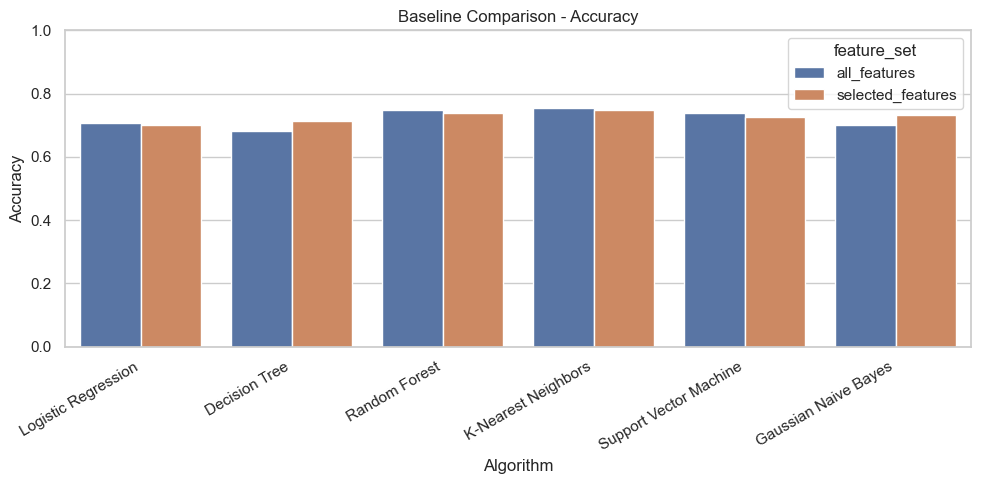

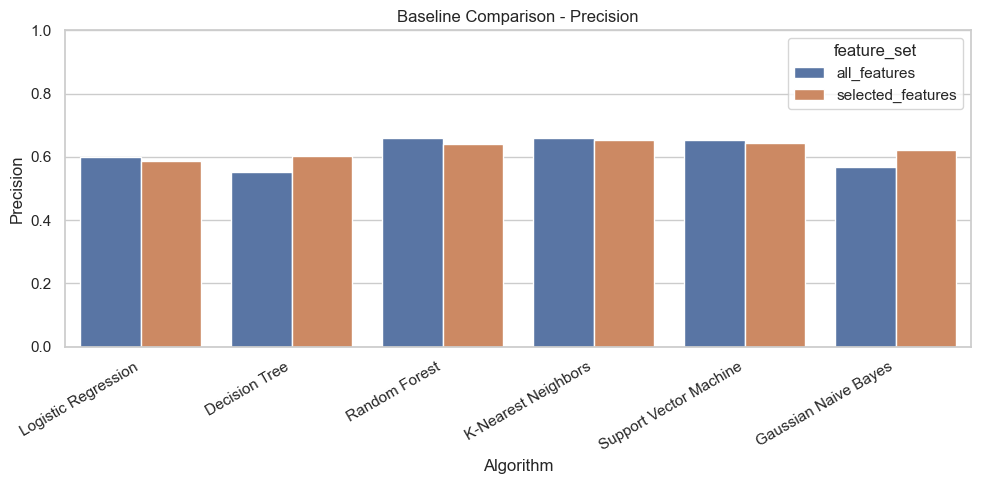

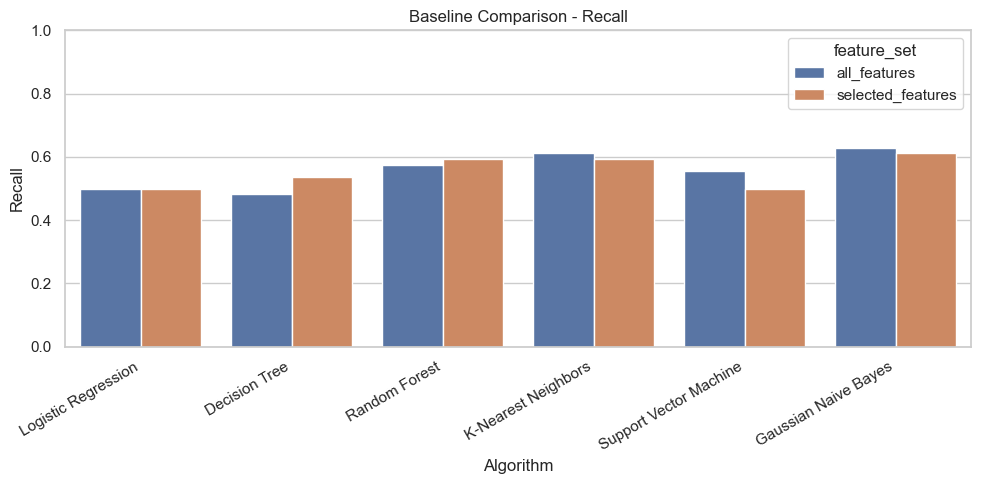

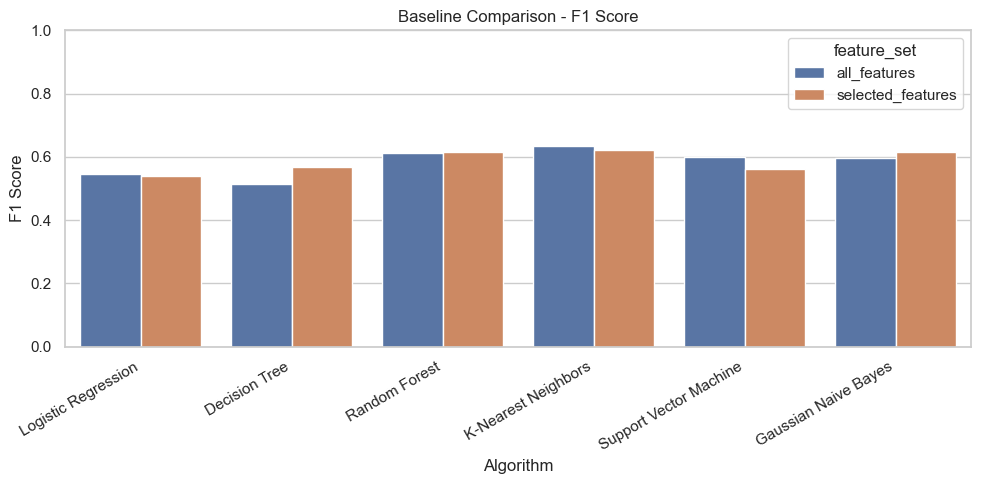

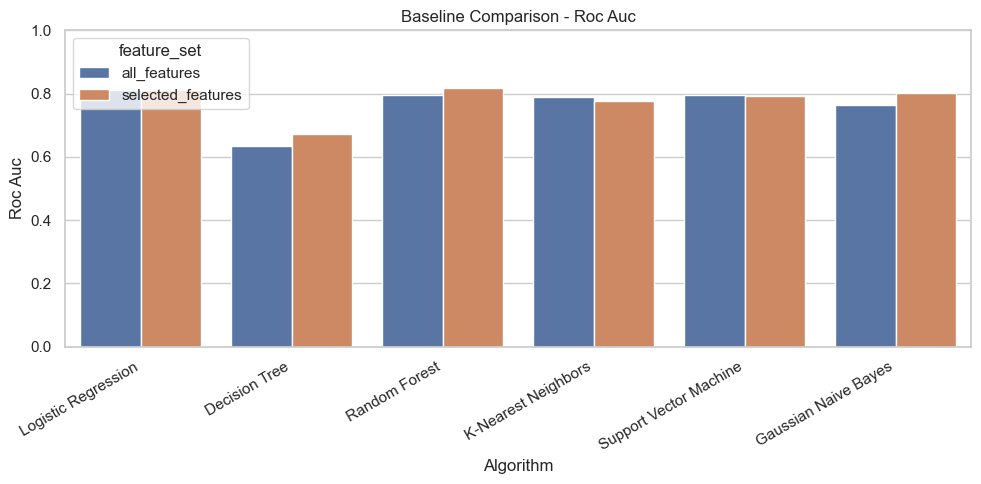

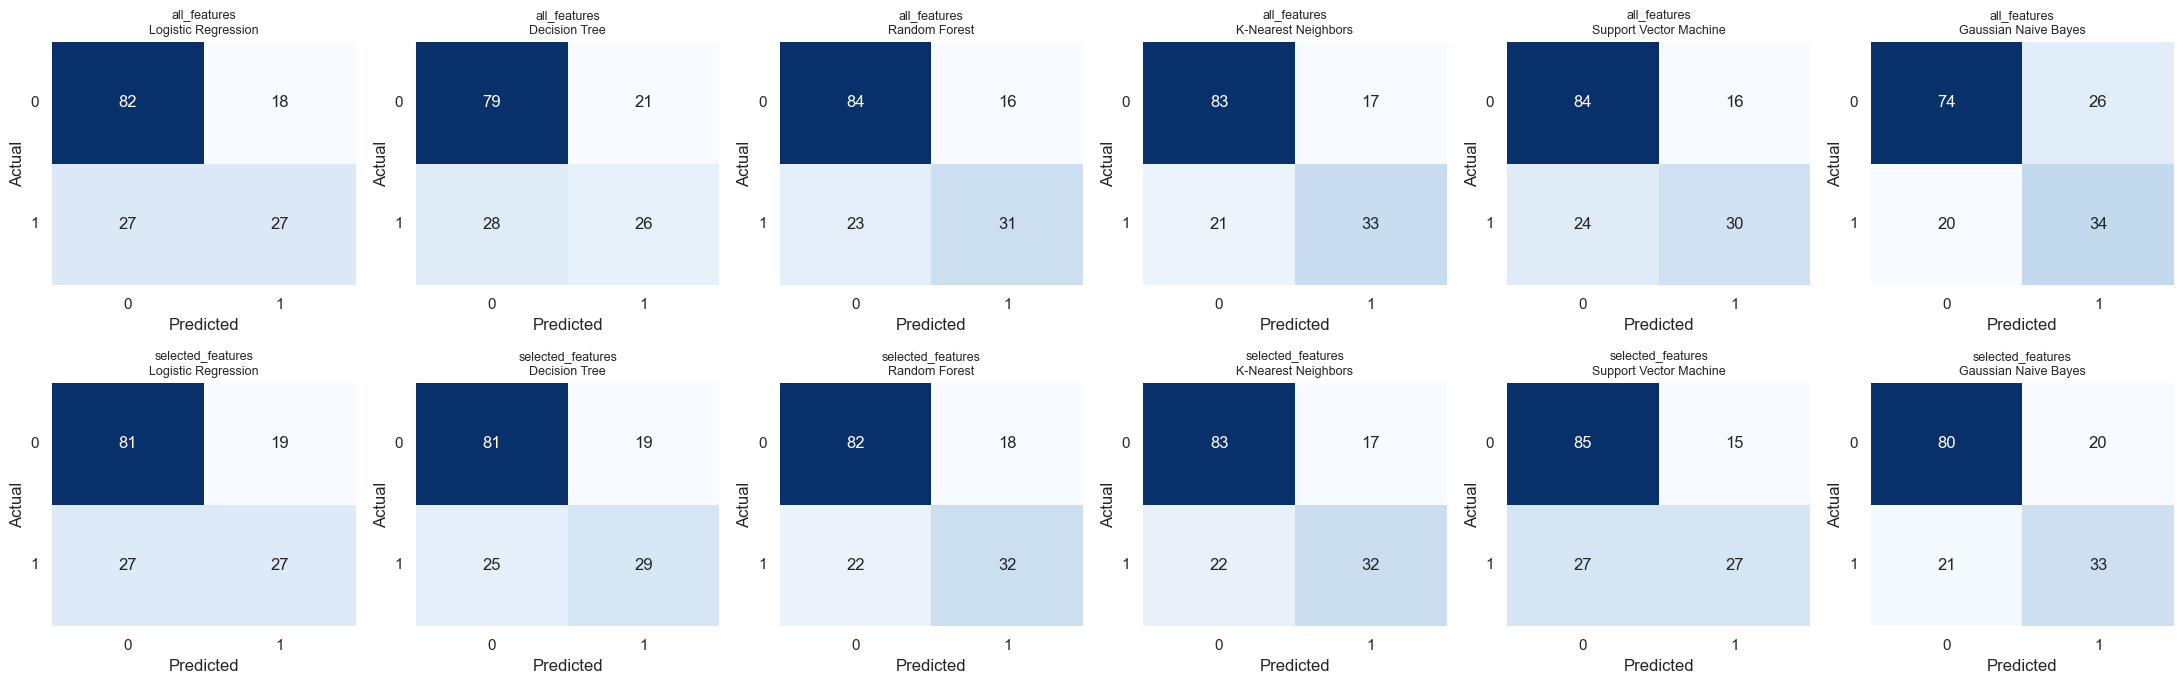

Saved figures:
- outputs\figures\week_09\accuracy_comparison.png
- outputs\figures\week_09\confusion_matrix_grid.png
- outputs\figures\week_09\f1_score_comparison.png
- outputs\figures\week_09\precision_comparison.png
- outputs\figures\week_09\recall_comparison.png
- outputs\figures\week_09\roc_auc_comparison.png


In [10]:
plot_metrics = ["accuracy", "precision", "recall", "f1_score", "roc_auc"]

for metric in plot_metrics:
    plt.figure(figsize=(10, 5))
    ax = sns.barplot(data=metrics_df, x="algorithm", y=metric, hue="feature_set")
    ax.set_title(f"Baseline Comparison - {metric.replace('_', ' ').title()}")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_ylim(0, 1)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{metric}_comparison.png", dpi=150)
    plt.show()
    plt.close()

fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for index, row in confusion_matrix_df.iterrows():
    ax = axes.flat[index]
    matrix = np.array([[row["true_negative"], row["false_positive"]], [row["false_negative"], row["true_positive"]]])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    title_text = f"{row['feature_set']}\n{row['algorithm']}"
    ax.set_title(title_text, fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(["0", "1"])
    ax.set_yticklabels(["0", "1"], rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_grid.png", dpi=150)
plt.show()
plt.close()

print("Saved figures:")
for file_path in sorted(FIGURES_DIR.glob("*.png")):
    print(f"- {FIGURES_RELATIVE_DIR / file_path.name}")

## 11. Validation Checks



In [15]:
required_tables = [
    "feature_set_summary.csv",
    "train_test_split_summary.csv",
    "train_test_split_indices.csv",
    "algorithm_summary.csv",
    "model_metrics.csv",
    "confusion_matrices.csv",
    "all_features_vs_selected_features.csv",
]

required_figures = [
    "accuracy_comparison.png",
    "precision_comparison.png",
    "recall_comparison.png",
    "f1_score_comparison.png",
    "roc_auc_comparison.png",
    "confusion_matrix_grid.png",
]

validation_checks = []
validation_checks.append({"check": "Exactly 12 experiments completed", "status": "PASS" if len(metrics_df) == 12 else "FAIL", "evidence": f"experiments={len(metrics_df)}"})
validation_checks.append({"check": "Six algorithms used", "status": "PASS" if metrics_df["algorithm"].nunique() == 6 else "FAIL", "evidence": f"algorithms={metrics_df['algorithm'].nunique()}"})
validation_checks.append({"check": "Two feature-set experiments used", "status": "PASS" if metrics_df["feature_set"].nunique() == 2 else "FAIL", "evidence": f"feature_sets={metrics_df['feature_set'].nunique()}"})
validation_checks.append({"check": "All metrics generated", "status": "PASS" if metrics_df[["accuracy", "precision", "recall", "f1_score", "roc_auc", "training_time_seconds"]].notna().all().all() else "FAIL", "evidence": "Checked required metric columns for missing values."})
validation_checks.append({"check": "All confusion matrices generated", "status": "PASS" if len(confusion_matrix_df) == 12 else "FAIL", "evidence": f"confusion_matrices={len(confusion_matrix_df)}"})
validation_checks.append({"check": "All model files saved", "status": "PASS" if all(path.exists() for path in model_paths) else "FAIL", "evidence": f"model_files={sum(path.exists() for path in model_paths)}"})
validation_checks.append({"check": "Required tables exist", "status": "PASS" if all((TABLES_DIR / file_name).exists() for file_name in required_tables) else "FAIL", "evidence": f"required_tables={len(required_tables)}"})
validation_checks.append({"check": "Required figures exist", "status": "PASS" if all((FIGURES_DIR / file_name).exists() for file_name in required_figures) else "FAIL", "evidence": f"required_figures={len(required_figures)}"})

validation_check_df = pd.DataFrame(validation_checks)
validation_check_df.to_csv(TABLES_DIR / "validation_checks.csv", index=False)
display(validation_check_df)

if not (validation_check_df["status"] == "PASS").all():
    failed = validation_check_df[validation_check_df["status"] != "PASS"]
    raise RuntimeError(f"Week 9 validation failed: {failed.to_dict(orient='records')}")

,check,status,evidence
0,Exactly 12 experiments completed,PASS,experiments=12
1,Six algorithms used,PASS,algorithms=6
2,Two feature-set experiments used,PASS,feature_sets=2
3,All metrics generated,PASS,Checked required metric columns for missing va...
4,All confusion matrices generated,PASS,confusion_matrices=12
5,All model files saved,PASS,model_files=12
6,Required tables exist,PASS,required_tables=7
7,Required figures exist,PASS,required_figures=6


## 12. Suggested Candidate for Architect Review

suggests a candidate model for human review based on balanced metric evidence. It does not declare a final best algorithm.

In [18]:
candidate_df = metrics_df.copy()
candidate_df["candidate_score"] = candidate_df[["accuracy", "precision", "recall", "f1_score", "roc_auc"]].mean(axis=1)
candidate_df = candidate_df.sort_values("candidate_score", ascending=False).reset_index(drop=True)

suggested_candidate = candidate_df.iloc[0]
suggested_candidate_table = candidate_df[[
    "experiment",
    "algorithm",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "roc_auc",
    "candidate_score",

]].copy()
suggested_candidate_table.to_csv(TABLES_DIR / "suggested_candidate_model.csv", index=False)

display(suggested_candidate_table.round(4).head(5))
print("Suggested candidate for architect review:")
print(f"{suggested_candidate['algorithm']} using {suggested_candidate['experiment']}")
print("This is a suggested candidate only, not a final best algorithm decision.")

,experiment,algorithm,accuracy,precision,recall,f1_score,roc_auc,candidate_score
0,Experiment A - All Features,K-Nearest Neighbors,0.7532,0.6600,0.6111,0.6346,0.7886,0.6895
1,Experiment B - Selected Features,Random Forest,0.7403,0.6400,0.5926,0.6154,0.8186,0.6814
2,Experiment A - All Features,Random Forest,0.7468,0.6596,0.5741,0.6139,0.7969,0.6782
3,Experiment B - Selected Features,K-Nearest Neighbors,0.7468,0.6531,0.5926,0.6214,0.7756,0.6779
4,Experiment B - Selected Features,Gaussian Naive Bayes,0.7338,0.6226,0.6111,0.6168,0.8017,0.6772


Suggested candidate for architect review:
K-Nearest Neighbors using Experiment A - All Features
This is a suggested candidate only, not a final best algorithm decision.


## 13.Summary Report


In [24]:
top_rows = suggested_candidate_table.round(4).head(6)
def dataframe_to_markdown_table(table):
    display_table = table.copy()
    display_table = display_table.astype(str)
    headers = list(display_table.columns)
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for _, table_row in display_table.iterrows():
        lines.append("| " + " | ".join(str(table_row[column]) for column in headers) + " |")
    return "\n".join(lines)

comparison_rows = comparison_df.round(4)

report_lines = [
    "# Diabetes Prediction Using Machine Learning",
    "",
    "##Summary: Baseline Model Development",
    "",
    "trained and compared baseline machine-learning models for diabetes prediction using a fixed stratified 80/20 train/test split with random_state = 42.",
    "",
    "No hyperparameter tuning, cross-validation, threshold optimization, feature engineering, data augmentation, sampling technique, deployment, or medical interpretation was performed.",
    "",
    "## Experiments",
    "",
    "- Experiment A: all 8 input features.",
    "- Experiment B: 5 selected features.",
    "- Algorithms: Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors, Support Vector Machine, Gaussian Naive Bayes.",
    "- Total experiments completed: 12.",
    "",
    "## Validation Summary",
    "",
]
for _, row in validation_check_df.iterrows():
    report_lines.append(f"- {row['check']}: {row['status']} ({row['evidence']})")
    
report_lines += [
    "",
    "## Experiment Results",
    "",
    dataframe_to_markdown_table(metrics_df.sort_values(["experiment", "algorithm"]).round(4)),
    "",
    "## All Features vs Selected Features Comparison",
    "",
    dataframe_to_markdown_table(comparison_rows),
    "",
    "## Suggested Candidate Model",
    "",
    f"Suggested candidate for architect review: {suggested_candidate['algorithm']} using {suggested_candidate['experiment']}.",
    "",
    "This is not a final best-algorithm decision. It is a candidate suggestion based on the average of Accuracy, Precision, Recall, F1 Score, and ROC AUC for review in the next stage.",
    "",
    "## Concerns and Limitations",
    "",
    "- The dataset contains only 768 records and represents a specific population.",
    "- The target classes are moderately imbalanced.",
    "- Results are based on one fixed train/test split only.",
    "- Baseline models were not tuned.",
    "- This project is educational and should not be interpreted as a medical diagnosis system.",
    "",
    "## Status",
    "",
    "READY_FOR_ARCHITECT_REVIEW",
]

report_path = REPORTS_DIR / "summary.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"summary report saved to:{report_path.name}")

summary report saved to:summary.md
